# Logistic regression

**Logistic regression** is a supervised learning algorithm used for **binary classification**, predicting whether an input belongs to one of two classes. It models the probability of an outcome using a sigmoid function, which maps inputs to a probability between 0 and 1. By adjusting weights through optimization, logistic regression finds the best decision boundary for separating classes.

## Outline
1. [Introduction](#1-introduction)
2. [The sigmoid function](#2-the-sigmoid-function)
3. [Binary cross entropy](#3-binary-cross-entropy)
4. [Data](#4-data)
5. [Gradient Computation for Logistic Regression with Binary Cross-Entropy Loss](#5-gradient-computation-for-logistic-regression-with-binary-cross-entropy-loss)
6. [Logistic regression implementation](#6-logistic-regression-implementation)
7. [Example usage](#7-example-usage)
8. [Testing with two features](#8-testing-with-two-features)
   - [A > B: Train and test from CSV data](#81-ab)
   - [A red corner](#82-a-red-corner)
9. [Polynomial logistic regression: Circle](#9-polynomial-logistic-regression-circle)
10. [Ideas to Deepen Your Knowledge](#10-ideas-to-deepen-your-knowledge)


## 1. Introduction
This Jupyter notebook implements logistic regression optimizing binary cross entropy loss using only the NumPy library (and MatPlotLib for display). It includes all the derivations of equations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

np.set_printoptions(precision=2)

## 2. The sigmoid function

The sigmoid function is a smooth, S-shaped function that maps any real-valued number to a value between 0 and 1. It can be interpreted as a smooth step function, which is particularly useful in binary classification tasks. The sigmoid function is defined as:
It is defined mathematically as:

$$
\sigma(z) = \frac{1}{1+e^{-z}}
\\
\sigma'(z) = \sigma(z)(1 - \sigma(z))
$$

In [2]:
def sigma(z):
    """The sigmoid function."""
    return 1 / (1 + np.e**(-1*z))

def d_sigma(z):
    """The derivative of the sigmoid function."""
    return sigma(z) * (1 - sigma(z))

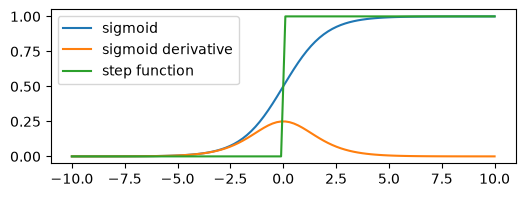

In [3]:
# Plot the sigmoid, its derivative and the step function
# ______________________________________________________
x = np.linspace(-10, 10, 100)
y1 = sigma(x)
y2 = d_sigma(x)

# set figure size
plt.figure(figsize=(6, 2))
plt.plot(x, y1, label='sigmoid')
plt.plot(x, y2, label='sigmoid derivative')
plt.plot(x, np.where(x >= 0, 1, 0), label='step function')
plt.legend()
plt.show()

## 3. Binary cross entropy

Cross-entropy measures how well one probability distribution predicts another. Its range is $[0, \infty)$, with 0 indicating perfect prediction. In binary classification, the binary cross-entropy (BCE) loss quantifies the difference between predicted probabilities and actual binary labels. 

Let $n$ be the number of examples and $m$ the number of features. For one example $i$, the **BCE loss** is:

$$
L^{(i)} = -\left( y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right)
$$

For $n$ examples, the average BCE loss is 

$$
\mathcal{L} = \frac{1}{n} \sum_{i=1}^{n} L^{(i)} = -\frac{1}{n} \sum_{i=1}^{n} \left( y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right)
$$


In [4]:
# Binary cross entropy
# import numpy as np

def binary_cross_entropy(y, y_hat):
    """Compute mean binary cross entropy across n examples.
    
    Parameters:
    y (array-like): n binary labels (0 or 1), one-dimensional or column-shaped.
    y_hat (array-like): n predicted probabilities, one-dimensional or column-shaped.

    Returns:
    float: Mean binary cross entropy across n examples.
    """
    y = np.asarray(y).ravel()
    y_hat = np.asarray(y_hat).ravel()
    y_hat = np.clip(y_hat, 1e-15, 1 - 1e-15)     # to avoid log(0)
    return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))   #BCE loss averaged across n examples



In [5]:
# These vectors contain n=8 examples.
y = [0, 0, 0, 0, 1, 1, 1, 1]
y_pred = [0.01, 0.0001, 0.2, 0.3, 0.9, 0.99, 0.9988, 0.99999]    # because of the sigmoid function, the values are in the interval (0, 1): never 0 or 1

print(binary_cross_entropy(y, y_pred))


0.08832380103057799


## 4. Data
We have artificial data with $n=100$ examples, one feature ($m=1$; the person's weight), and one binary target (whether they are obese). The feature matrix $X$ has shape $(n,m)=(100,1)$, and the labels are stored as a one-dimensional array with shape $(n,)=(100,)$. The model reshapes labels internally to $(n,1)$ for its matrix calculations.

**Scaling note:** This small example has no train/test split, so the scaler is fitted to all 100 feature values only to demonstrate scaling. For model evaluation, split the data first, fit the scaler on training features only, then use that same fitted scaler to transform both training and test features. Fitting on test data leaks information about the held-out set into the training process.

n=100 examples, m=1 feature(s); y has shape (100,)


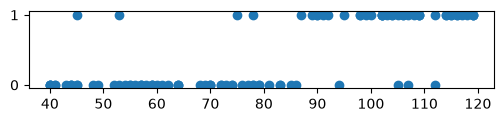

In [6]:
# Data

# weight in kgs
x = [40, 40, 40, 40, 41, 41, 43, 44, 44, 44, 45, 45, 45, 48, 49, 52, 53, 53, 54, 55, 55, 56, 57, 57, 57, 58, 59, 59, 59, 60, 61, 62, 64, 64, 64, 68, 69, 70, 70, 70, 72, 72, 73, 74, 74, 75, 76, 77, 78, 78, 78, 79, 79, 81, 83, 83, 85, 86, 87, 89, 90, 90, 91, 92, 94, 95, 98, 98, 99, 100, 102, 102, 102, 102, 103, 104, 104, 105, 105, 106, 106, 107, 107, 108, 109, 109, 109, 112, 112, 114, 114, 115, 115, 116, 116, 117, 118, 119, 119, 119]
# obese yes or no
y = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

# Arrange data as n rows (examples) and m columns (features)
x = np.array(x).reshape(-1, 1)
y = np.array(y)
n_examples, m_features = x.shape
print(f"n={n_examples} examples, m={m_features} feature(s); y has shape {y.shape}")

# scatter plot
plt.figure(figsize=(6, 1))
plt.scatter(x[:, 0], y)


In [7]:
class MinMaxScaler:
    def __init__(self):
        self.X_min = None
        self.X_max = None

    def fit(self, X):
        self.X_min = X.min(axis=0)     # one minimum per feature across n training examples
        self.X_max = X.max(axis=0)     # one maximum per feature across n training examples

    def transform(self, X):            # apply the scaling
        return 2 * (X - self.X_min) / (self.X_max - self.X_min) - 1
    
    def inverse_transform(self, X):    # reverse the scaling
        return (X + 1) * (self.X_max - self.X_min) / 2 + self.X_min
    


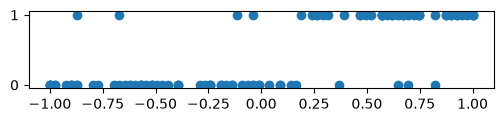

In [8]:
# Demonstration only: scale all data here because this example has no train/test split.
# For evaluation, fit on X_train only, then transform both X_train and X_test.

mm_scaler = MinMaxScaler()
mm_scaler.fit(x)                  # demonstration: learn parameters from all 100 examples
x = mm_scaler.transform(x)        # apply the scaling

# scatter plot
plt.figure(figsize=(6, 1))
plt.scatter(x, y)


## 5. Gradient Computation for Logistic Regression

We derive the gradients needed to train logistic regression using binary cross-entropy loss and gradient descent.

### 5.1 Forward pass

For training example $i$, with $m$ features, the weighted input is

$$
z^{(i)} = \sum_{j=1}^{m} x_j^{(i)}w_j + b.
$$

The sigmoid transforms this input into a predicted probability:

$$
\hat{y}^{(i)} = \sigma(z^{(i)}) = \frac{1}{1+e^{-z^{(i)}}}.
$$

### 5.2 Binary cross-entropy loss

For one example, the loss is

$$
L^{(i)} = -\left[
y^{(i)}\log\hat{y}^{(i)}
+(1-y^{(i)})\log(1-\hat{y}^{(i)})
\right].
$$

The average loss across $n$ examples is

$$
\mathcal{L} = \frac{1}{n}\sum_{i=1}^{n}L^{(i)}.
$$

Our goal is to compute the derivatives of $\mathcal{L}$ with respect to the weights $w_j$ and bias $b$.

### 5.3 Derivative of the loss with respect to the prediction

For a single example, differentiating BCE gives

$$
\frac{\partial L^{(i)}}{\partial \hat{y}^{(i)}}
= -\frac{y^{(i)}}{\hat{y}^{(i)}}
+\frac{1-y^{(i)}}{1-\hat{y}^{(i)}}.
$$

### 5.4 Derivative of the prediction with respect to the weights

The derivative of the sigmoid is

$$
\sigma'(z) = \sigma(z)(1-\sigma(z)).
$$

Therefore,

$$
\frac{\partial \hat{y}^{(i)}}{\partial z^{(i)}}
=\hat{y}^{(i)}(1-\hat{y}^{(i)}).
$$

Since $z^{(i)}=\sum_j x_j^{(i)}w_j+b$,

$$
\frac{\partial z^{(i)}}{\partial w_j}=x_j^{(i)},
\qquad
\frac{\partial z^{(i)}}{\partial b}=1.
$$

Applying the chain rule,

$$
\frac{\partial\hat{y}^{(i)}}{\partial w_j}
=\hat{y}^{(i)}(1-\hat{y}^{(i)})x_j^{(i)}.
$$

### 5.5 Combining the derivatives

Using the chain rule,

$$
\frac{\partial L^{(i)}}{\partial w_j}
=
\frac{\partial L^{(i)}}{\partial\hat{y}^{(i)}}
\frac{\partial\hat{y}^{(i)}}{\partial w_j}.
$$

Substituting the derivatives,

$$
\frac{\partial L^{(i)}}{\partial w_j}
=
\left(
-\frac{y^{(i)}}{\hat{y}^{(i)}}
+\frac{1-y^{(i)}}{1-\hat{y}^{(i)}}
\right)
\hat{y}^{(i)}(1-\hat{y}^{(i)})x_j^{(i)}.
$$

The terms simplify to

$$
\boxed{
\frac{\partial L^{(i)}}{\partial w_j}
=(\hat{y}^{(i)}-y^{(i)})x_j^{(i)}
}
$$

For the average loss over all examples,

$$
\boxed{
\frac{\partial\mathcal{L}}{\partial w_j}
=\frac{1}{n}\sum_{i=1}^{n}
(\hat{y}^{(i)}-y^{(i)})x_j^{(i)}
}
$$

Similarly, because $\partial z^{(i)}/\partial b=1$,

$$
\boxed{
\frac{\partial\mathcal{L}}{\partial b}
=\frac{1}{n}\sum_{i=1}^{n}
(\hat{y}^{(i)}-y^{(i)})
}
$$

### 5.6 Gradient descent update

We update each weight in the direction opposite to the gradient:

$$
\boxed{
w_j \leftarrow w_j-\eta\frac{1}{n}
\sum_{i=1}^{n}(\hat{y}^{(i)}-y^{(i)})x_j^{(i)}
}
$$

And the bias:

$$
\boxed{
b \leftarrow b-\eta\frac{1}{n}
\sum_{i=1}^{n}(\hat{y}^{(i)}-y^{(i)})
}
$$

where $\eta$ is the learning rate.

**Takeaway.** For logistic regression with BCE loss, the gradient is particularly simple: the prediction error $(\hat{y}^{(i)}-y^{(i)})$ multiplied by the corresponding feature value. The gradient for the bias is the average prediction error.


## 6. Logistic regression implementation
We need to define a class the methods:
- `__init__(self, [parameters])`, which initializes the classifier
- `fit(self, X, y)`, which fits the parameters of logistic regression to the data
- `predict_proba(self, X)`, which predicts probabilities
- `predict(self, X)`, which makes binary predictions
And auxiliary method
- `gradient_descent_step(self, X, y)`, which calculates the gradient for each weight w.r.t. the loss and updates the weights


In [9]:

class LogisticRegression:
    def __init__(self, epochs=1000, learning_rate=0.1, verbose=False, print_every=100):
        self.epochs = epochs
        self.learning_rate = learning_rate
        self.verbose = verbose
        self.print_every = print_every

    def fit(self, X, y):
        n, m = X.shape
        y = np.asarray(y).reshape(-1, 1)

        self.w = np.zeros((m, 1))
        self.b = 0.0

        for epoch in range(self.epochs):
            # Forward pass
            z = X @ self.w + self.b
            y_hat = sigma(z)

            # Gradients of BCE + sigmoid
            error = y_hat - y
            dw = X.T @ error / n
            db = np.mean(error)

            # Gradient descent
            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

            if self.verbose and (epoch % self.print_every == 0 or epoch == self.epochs - 1):
                loss = binary_cross_entropy(y, self.predict_proba(X))
                print(f"Epoch {epoch + 1:4d}: loss = {loss:.4f}")

        return self

    def predict_proba(self, X):
        return sigma(X @ self.w + self.b)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).ravel()    #ravel() converts a NumPy array into a one-dimensional array


## 7. Example usage

In [10]:
# Example usage:
np.random.seed(42)  # For reproducibility

my_model = LogisticRegression(verbose=True)   # n=100 examples, m=1 feature, one output per example
my_model.fit(x, y)
y_hat = my_model.predict_proba(x)

Epoch    1: loss = 0.6874
Epoch  101: loss = 0.4387
Epoch  201: loss = 0.3822
Epoch  301: loss = 0.3611
Epoch  401: loss = 0.3513
Epoch  501: loss = 0.3461
Epoch  601: loss = 0.3431
Epoch  701: loss = 0.3413
Epoch  801: loss = 0.3402
Epoch  901: loss = 0.3395
Epoch 1000: loss = 0.3390


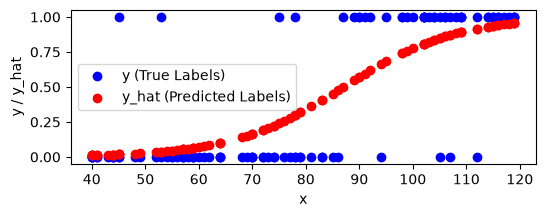

In [11]:
# Plot the fitted logistic regression
#___________________________________________________________________
plt.figure(figsize=(6, 2))
plt.scatter(mm_scaler.inverse_transform(x[:, 0]), y, color='blue', label='y (True Labels)')
plt.scatter(mm_scaler.inverse_transform(x[:, 0]), y_hat.ravel(), color='red', label='y_hat (Predicted Labels)')
plt.xlabel('x')
plt.ylabel('y / y_hat')
plt.legend()
plt.show()

In [12]:
# Tra

## 8. Testing with two features
### 8.1 A>B

Use the provided CSV files to train on $n_{\mathrm{train}}=300$ examples and evaluate on $n_{\mathrm{test}}=5000$ held-out examples. Each example has $m=3$ features ($A$, $B$, and $C$); the binary target is whether $A>B$.

We use the parameter $n_training$ to specify how many examples are used for training.


Training: X=(30, 3), y=(30,); test: X=(5000, 3), y=(5000,)


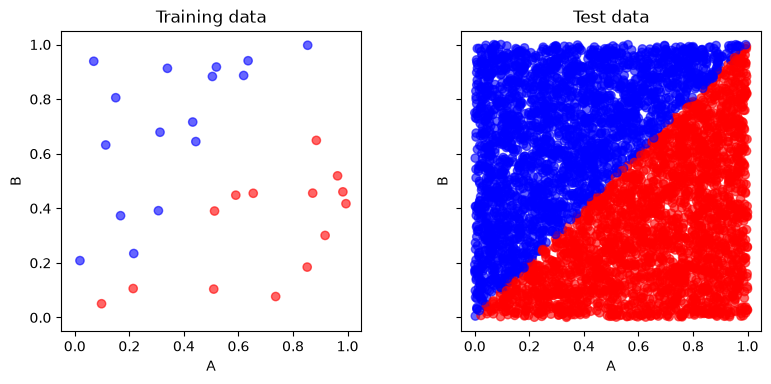

In [13]:
# Locate data/a_gt_b whether the notebook runs from its folder or the Hands-on root.
n_training = 30

data_dir = Path("../../data/a_gt_b")
train_df = pd.read_csv(data_dir /"trainABC.csv")
train_df = train_df.sample(n_training)
test_df = pd.read_csv(data_dir / "testABC.csv")

feature_columns = ["A", "B", "C"]
X_ab_train = train_df[feature_columns].to_numpy(dtype=float)
y_ab_train = train_df["A>B"].astype(int).to_numpy()
X_ab_test = test_df[feature_columns].to_numpy(dtype=float)
y_ab_test = test_df["A>B"].astype(int).to_numpy()
print(f"Training: X={X_ab_train.shape}, y={y_ab_train.shape}; test: X={X_ab_test.shape}, y={y_ab_test.shape}")

# Plot train and test examples, colored by whether A > B.
fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout="none", sharex=True, sharey=True)

axes[0].scatter(X_ab_train[:, 0], X_ab_train[:, 1], c=y_ab_train, cmap="bwr", vmin=0, vmax=1, alpha=0.6)
axes[0].set(xlabel="A", ylabel="B", title="Training data")
axes[0].set_box_aspect(1)

axes[1].scatter(X_ab_test[:, 0], X_ab_test[:, 1], c=y_ab_test, cmap="bwr", vmin=0, vmax=1, alpha=0.6)
axes[1].set(xlabel="A", ylabel="B", title="Test data")
axes[1].set_box_aspect(1)

# Fixed margins keep each square plotting area at 3 x 3 inches.
plt.subplots_adjust(left=0.1, right=0.975, bottom=0.18, top=0.93, wspace=1/3)
plt.show()

In [14]:
# Fit on the training CSV, then evaluate on the separate test CSV.
np.random.seed(42)
ab_model = LogisticRegression(epochs=5000, learning_rate=0.1)
ab_model.fit(X_ab_train, y_ab_train)
y_ab_train_pred = ab_model.predict(X_ab_train)
y_ab_test_pred = ab_model.predict(X_ab_test)
test_accuracy = np.mean(y_ab_test_pred == y_ab_test)
print(f"Test accuracy: {test_accuracy:.1%}")

Test accuracy: 95.6%


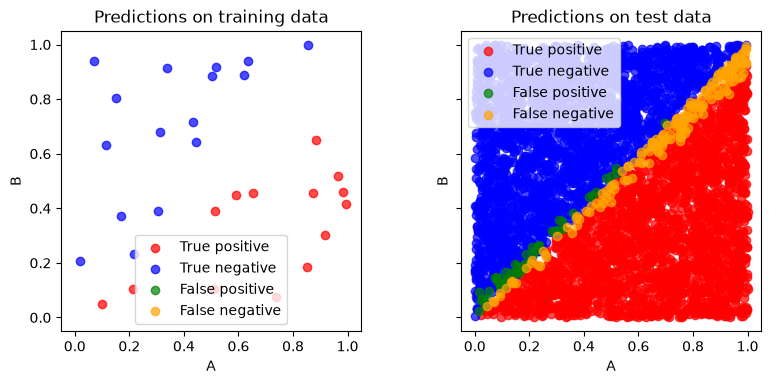

In [15]:
y_ab_train_pred = ab_model.predict(X_ab_train)
y_ab_test_pred = ab_model.predict(X_ab_test)

categories = [
    (1, 1, "True positive", "red"),
    (0, 0, "True negative", "blue"),
    (0, 1, "False positive", "green"),
    (1, 0, "False negative", "orange"),
]

fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout="none", sharex=True, sharey=True)

for true_label, pred_label, name, color in categories:
    train_mask = (y_ab_train == true_label) & (y_ab_train_pred == pred_label)
    test_mask = (y_ab_test == true_label) & (y_ab_test_pred == pred_label)

    axes[0].scatter(
        X_ab_train[train_mask, 0], X_ab_train[train_mask, 1],
        color=color, alpha=0.7, label=name,
    )
    axes[1].scatter(
        X_ab_test[test_mask, 0], X_ab_test[test_mask, 1],
        color=color, alpha=0.7, label=name,
    )


axes[0].set(xlabel="A", ylabel="B", title="Predictions on training data")
axes[0].set_box_aspect(1)
axes[0].legend()

axes[1].set(xlabel="A", ylabel="B", title="Predictions on test data")
axes[1].set_box_aspect(1)
axes[1].legend()

# Fixed margins keep each square plotting area at 3 x 3 inches.
plt.subplots_adjust(left=0.1, right=0.975, bottom=0.18, top=0.93, wspace=1/3)
plt.show()

### 8.2 A red corner
This synthetic example uses $n_{\mathrm{train}}=30$ training examples and $n_{\mathrm{test}}=1000$ test examples, each with $m=2$ features. Thus, $X_{\mathrm{train}}$ has shape $(30,2)$ and $X_{\mathrm{test}}$ has shape $(1000,2)$. Labels are one-dimensional arrays with shapes $(30,)$ and $(1000,)$; the custom model reshapes training labels internally for its matrix calculations.

Training: n=30, m=2; test: n=1000, m=2


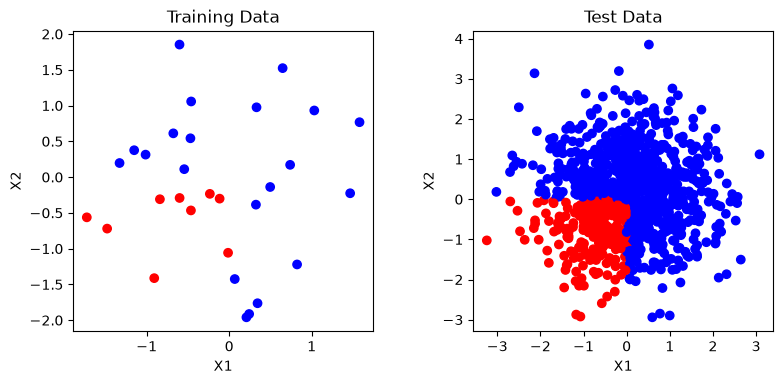

In [16]:
# Generate data
#_____________________________________________
# Generate data with n_train=30 and n_test=1000 examples, each with m=2 features.
# These data are not linearly separable, so it is not expected that the logistic regression will perform well on this dataset.
np.random.seed(42)
n_train = 30
n_test = 1000
m_features = 2
X_corner_train = np.random.randn(n_train, m_features)
X_corner_test = np.random.randn(n_test, m_features)
print(f"Training: n={n_train}, m={m_features}; test: n={n_test}, m={m_features}")
# Store one label per example in one-dimensional arrays; the negative-negative quadrant has label 1.
y_corner_train = ((X_corner_train[:, 0] < 0) & (X_corner_train[:, 1] < 0)).astype(int)
y_corner_test = ((X_corner_test[:, 0] < 0) & (X_corner_test[:, 1] < 0)).astype(int)

# scatter plot the two datasets side by side
plt.figure(figsize=(8, 4), layout="none")

plt.subplot(1, 2, 1)
plt.gca().set_box_aspect(1)
plt.scatter(X_corner_train[:, 0], X_corner_train[:, 1], c=y_corner_train, cmap='bwr')
plt.title('Training Data')
plt.xlabel('X1')
plt.ylabel('X2')

plt.subplot(1, 2, 2)
plt.gca().set_box_aspect(1)
plt.scatter(X_corner_test[:, 0], X_corner_test[:, 1], c=y_corner_test, cmap='bwr')
plt.title('Test Data')
plt.xlabel('X1')
plt.ylabel('X2')

# Fixed margins keep each square plotting area at 3 x 3 inches.
plt.subplots_adjust(left=0.1, right=0.975, bottom=0.18, top=0.93, wspace=1/3)
plt.show()


In [17]:
# Initialize and fit the model
corner_model = LogisticRegression()
corner_model.fit(X_corner_train, y_corner_train)
# Make predictions
y_corner_pred = corner_model.predict(X_corner_test)

# Test accuracy
accuracy = np.mean(y_corner_pred == y_corner_test)
print(f"Test accuracy: {accuracy:.1%}")



Test accuracy: 86.2%


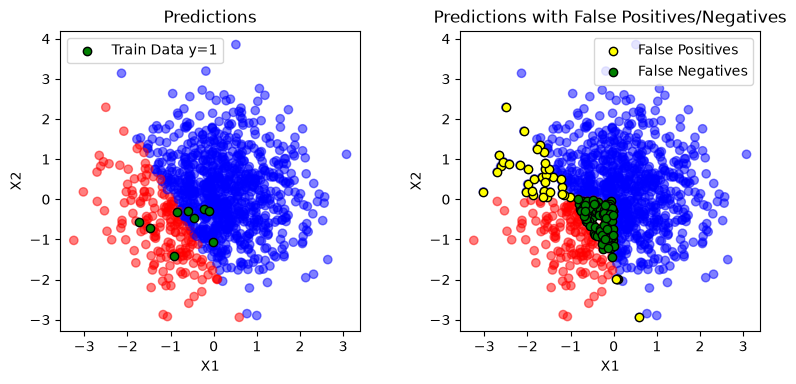

In [18]:
# Plot the results and compare it with training data and ground truth
plt.figure(figsize=(8, 4), layout="none")

# Left plot: Predictions
plt.subplot(1, 2, 1)
plt.gca().set_box_aspect(1)
plt.scatter(X_corner_test[:, 0], X_corner_test[:, 1], c=y_corner_pred, cmap='bwr', alpha=0.5)
plt.scatter(X_corner_train[y_corner_train == 1][:, 0], X_corner_train[y_corner_train == 1][:, 1], color='green', edgecolor='black', label='Train Data y=1')
plt.title('Predictions')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()

# Right plot: Predictions highlighting false positives and false negatives
plt.subplot(1, 2, 2)
plt.gca().set_box_aspect(1)
plt.scatter(X_corner_test[:, 0], X_corner_test[:, 1], c=y_corner_test, cmap='bwr', alpha=0.5)
fp = (y_corner_test == 0) & (y_corner_pred == 1)
fn = (y_corner_test == 1) & (y_corner_pred == 0)
plt.scatter(X_corner_test[fp, 0], X_corner_test[fp, 1], color='yellow', edgecolor='black', label='False Positives')
plt.scatter(X_corner_test[fn, 0], X_corner_test[fn, 1], color='green', edgecolor='black', label='False Negatives')
plt.title('Predictions with False Positives/Negatives')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()

# Fixed margins keep each square plotting area at 3 x 3 inches.
plt.subplots_adjust(left=0.1, right=0.975, bottom=0.18, top=0.93, wspace=1/3)
plt.show()

## 9. Polynomial logistic regression: Circle
Let's generate $n_{\mathrm{train}}=100$ training examples and $n_{\mathrm{test}}=1000$ test examples with $m=2$ features. The one-dimensional target arrays have shapes $(n_{\mathrm{train}},)$ and $(n_{\mathrm{test}},)$. The data are not linearly separable, but become separable after adding polynomial features.

Training: n=100, m=2; test: n=1000, m=2


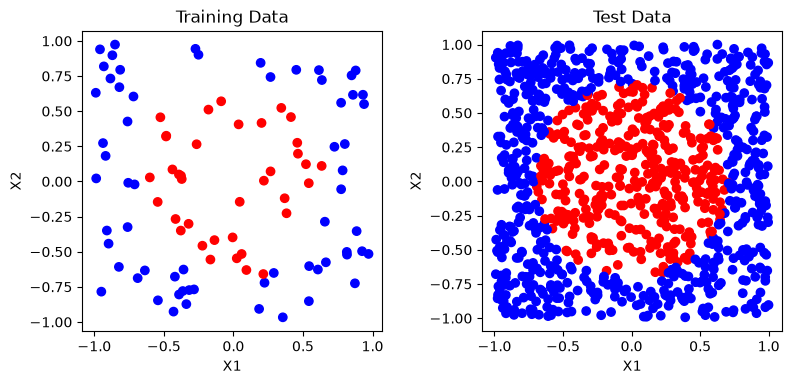

In [19]:
# Generate Data
#_____________________________________________________________
# Generate data with n_train=30 and n_test=1000 examples, each with m=2 features.
# These data are not linearly separable, so it is not expected that the logistic regression will perform well on this dataset.
np.random.seed(42)
n_train = 100
n_test = 1000
m_features = 2
X_train = np.random.uniform(-1, 1, size=(n_train, m_features))
X_test = np.random.uniform(-1, 1, size=(n_test, m_features))
print(f"Training: n={n_train}, m={m_features}; test: n={n_test}, m={m_features}")
y_train = ((X_train[:, 0]**2 + X_train[:, 1]**2) < 0.5).astype(int)
y_test = ((X_test[:, 0]**2 + X_test[:, 1]**2) < 0.5).astype(int)

# scatter plot the two datasets side by side
plt.figure(figsize=(8, 4), layout="none")

plt.subplot(1, 2, 1)
plt.gca().set_box_aspect(1)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='bwr')
plt.title('Training Data')
plt.xlabel('X1')
plt.ylabel('X2')

plt.subplot(1, 2, 2)
plt.gca().set_box_aspect(1)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='bwr')
plt.title('Test Data')
plt.xlabel('X1')
plt.ylabel('X2')

# Fixed margins keep each square plotting area at 3 x 3 inches.
plt.subplots_adjust(left=0.1, right=0.975, bottom=0.18, top=0.93, wspace=1/3)
plt.show()

In [20]:
# Add quadratic terms: x1², x1*x2, and x2²
def polynomial_features(X):
    x1, x2 = X[:, 0], X[:, 1]
    return np.column_stack((x1, x2, x1**2, x1 * x2, x2**2))

X_train_poly = polynomial_features(X_train)
X_test_poly = polynomial_features(X_test)

np.random.seed(42)
poly_model = LogisticRegression()
poly_model.fit(X_train_poly, y_train)

y_poly_pred = poly_model.predict(X_test_poly)

accuracy = np.mean(y_poly_pred == y_test)
print(f"Test accuracy: {accuracy:.1%}")

Test accuracy: 95.2%


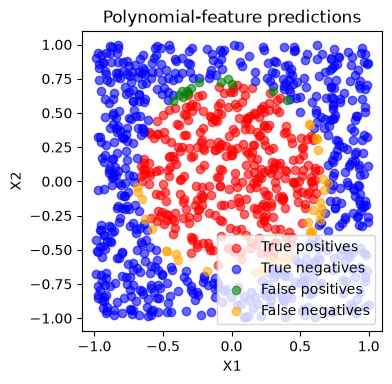

In [21]:
# Plot the decision boundary
#_____________________________________________

categories = [
    ((y_test == 1) & (y_poly_pred == 1), "True positives", "red"),
    ((y_test == 0) & (y_poly_pred == 0), "True negatives", "blue"),
    ((y_test == 0) & (y_poly_pred == 1), "False positives", "green"),
    ((y_test == 1) & (y_poly_pred == 0), "False negatives", "orange"),
]

plt.figure(figsize=(4, 4), layout="none")
plt.gca().set_box_aspect(1)
for mask, label, color in categories:
    plt.scatter(
        X_test[mask, 0],
        X_test[mask, 1],
        color=color,
        alpha=0.6,
        label=label,
    )

plt.title("Polynomial-feature predictions")
plt.xlabel("X1")
plt.ylabel("X2")
plt.legend(loc="lower right")
# Match the 3 x 3 inch plotting areas in the paired figures.
plt.subplots_adjust(left=0.2, right=0.95, bottom=0.18, top=0.93)
plt.show()

## 10. Ideas to Deepen Your Knowledge
- Compare the performance of our implementation of logistic regression to the one in SciKit-Learn.
- Use real datasets.
- Add the scaling/normalization of the input space in the fit function.
- Include L1 and/or L2 regularization.
- Implement the support for mini-batch stochastic gradient descent